Caricamento dati in corso...
Dataset caricati. Coppie di match estratte con successo: 546
Grafici generati con successo!


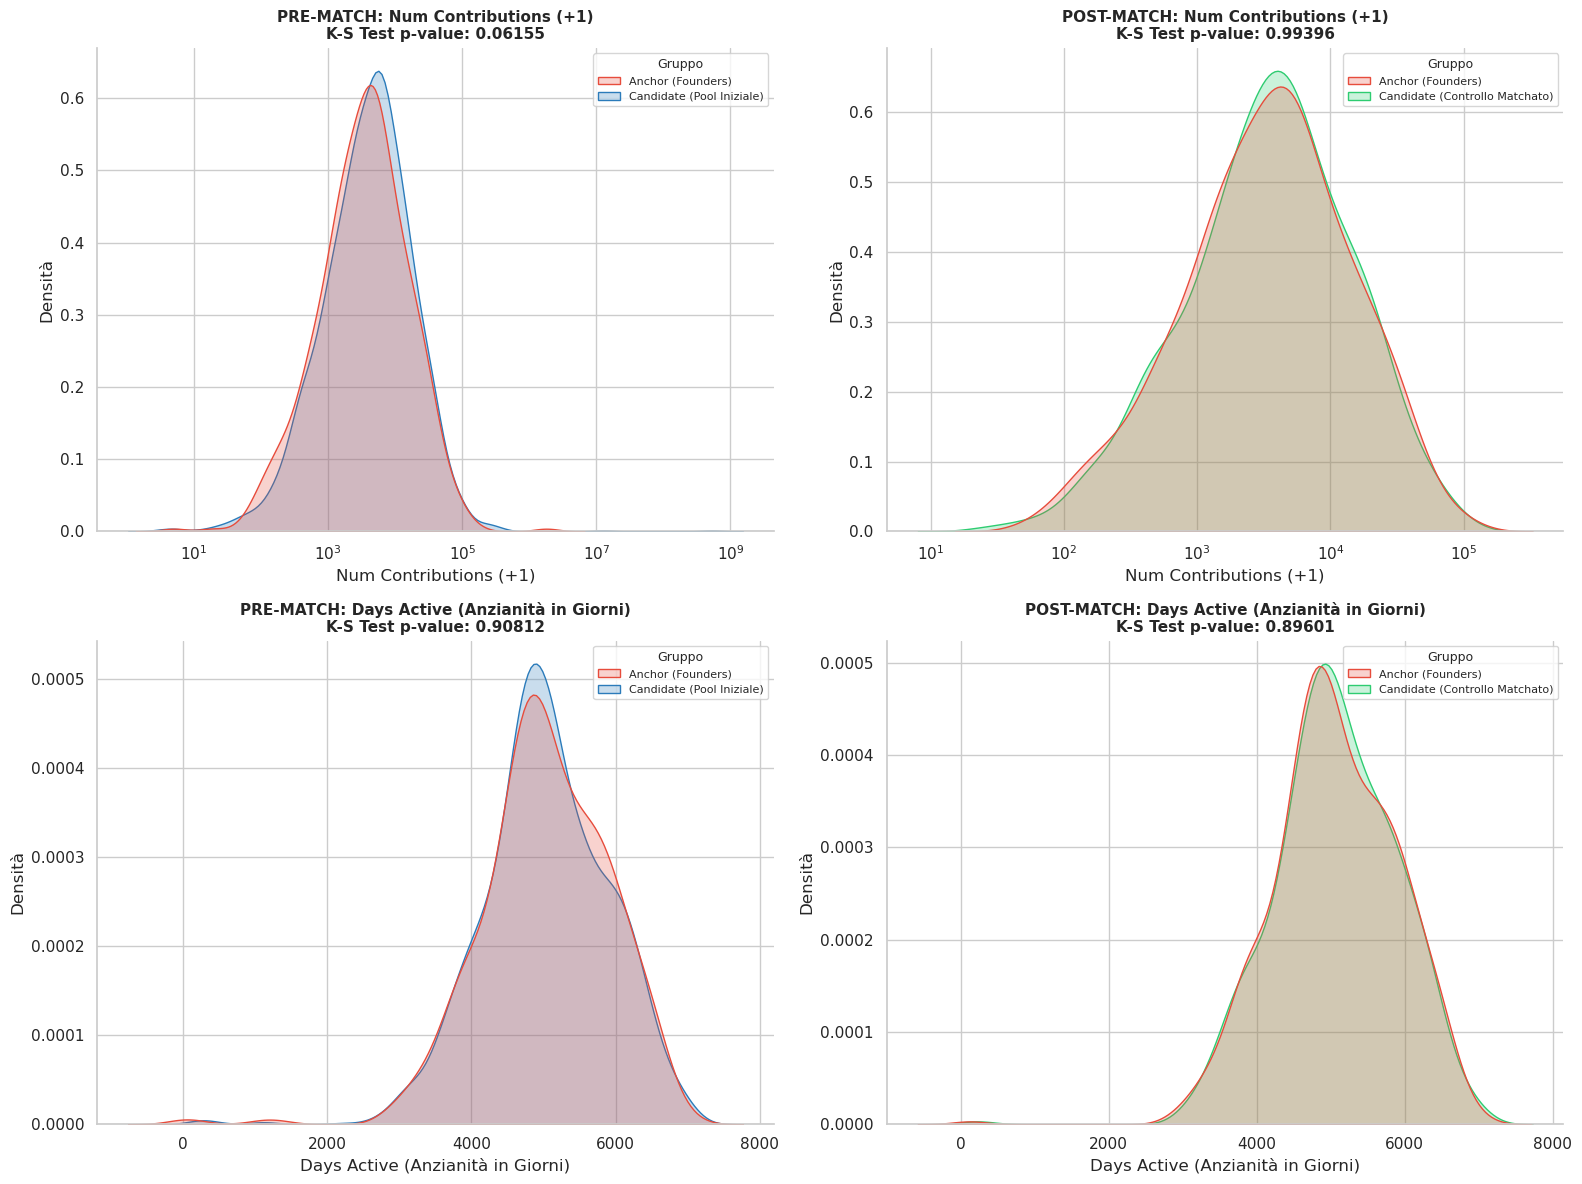

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kstest


# CARICAMENTO DEI DATASET

print("Caricamento dati in corso...")
df_anchors = pd.read_csv("../data/interim/anchors_test.csv")
df_candidates = pd.read_csv("../data/interim/candidates_test.csv")

# La matrice ha gli anchors come indice (riga) e i candidates come colonne
df_matrix = pd.read_csv("../data/raw/matching_matrix_raw.csv", index_col=0)

# Troviamo il momento più recente registrato
max_unix = max(df_anchors['active since'].max(), df_candidates['active since'].max())

# Calcoliamo l'anzianità reale in giorni (+1 per sicurezza statistica/logaritmica)
df_anchors['days_active'] = ((max_unix - df_anchors['active since']) / 86400) + 1
df_candidates['days_active'] = ((max_unix - df_candidates['active since']) / 86400) + 1


# ESTRAZIONE DEI GEMELLI (DALLA MATRICE DI MATCHING)

# Rimuoviamo eventuali anchor che non hanno superato i filtri iniziali (righe tutte NaN)
df_matrix_clean = df_matrix.dropna(how='all', axis=0)

# Per ogni Anchor (riga), trova il Candidate (colonna) con la distanza WMD MINIMA
# .idxmin(axis=1) restituisce una Serie: l'indice è l'Anchor, il valore è il Candidate matchato
best_candidates_series = df_matrix_clean.idxmin(axis=1)

# Estraiamo i dataframe allineati a coppie (coppie Anchor-Candidate reali)
# Usiamo .loc per preservare l'esatta corrispondenza 1:1 dei partner scelti
df_matched_anchors = df_anchors.set_index('username').loc[best_candidates_series.index].reset_index()
df_matched_candidates = df_candidates.set_index('username').loc[best_candidates_series.values].reset_index()

print(f"Dataset caricati. Coppie di match estratte con successo: {len(df_matched_anchors)}")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Definiamo le feature da analizzare e le loro impostazioni di scala
features_to_plot = [
    {"col": "num contributions", "label": "Num Contributions (+1)", "log": True},
    {"col": "days_active", "label": "Days Active (Anzianità in Giorni)", "log": False}
]

colors_pre = ["#e74c3c", "#2b7bba"]   # Rosso (Anchor) vs Blu (Tutti i Candidate)
colors_post = ["#e74c3c", "#2ecc71"]  # Rosso (Anchor) vs Verde (Solo i Candidate Scelti)


# CICLO DI GENERAZIONE GRAFICI E TEST STATISTICI

for row_idx, feat in enumerate(features_to_plot):
    col_name = feat["col"]
    display_label = feat["label"]
    use_log = feat["log"]
    

    # COLONNA 1: PRE-MATCH PLOT & TEST

    anchors_pre = df_anchors[[col_name]].copy()
    anchors_pre['Gruppo'] = 'Anchor (Founders)'
    
    candidates_pre = df_candidates[[col_name]].copy()
    candidates_pre['Gruppo'] = 'Candidate (Pool Iniziale)'
    
    df_pre_long = pd.concat([anchors_pre, candidates_pre], ignore_index=True)
    
    # Eseguiamo il test di Kolmogorov-Smirnov prima del matching
    stat_pre, p_pre = kstest(df_anchors[col_name], df_candidates[col_name])
    
    # Disegniamo la curva di densità smussata (KDE)
    sns.kdeplot(
        data=df_pre_long, x=col_name, hue='Gruppo', fill=True, alpha=0.25,
        log_scale=use_log, palette=colors_pre, common_norm=False, ax=axes[row_idx, 0]
    )
    axes[row_idx, 0].set_title(f"PRE-MATCH: {display_label}\nK-S Test p-value: {p_pre:.5f}", fontsize=11, fontweight='bold')
    axes[row_idx, 0].set_xlabel(display_label)
    axes[row_idx, 0].set_ylabel("Densità")

    # FIX FINESTRELLA: La rimpicciolisce e la sposta in alto a destra dentro il grafico
    sns.move_legend(
        axes[row_idx, 0], 
        loc="upper right",   # Sposta in alto a destra
        fontsize=8,          # Rimpicciolisce il testo delle opzioni
        title_fontsize=9,    # Rimpicciolisce il titolo "Gruppo"
        frameon=True         # Mette uno sfondo bianco semi-trasparente per non accavallarsi alle linee
    )
    

    # COLONNA 2: POST-MATCH PLOT & TEST

    anchors_post = df_matched_anchors[[col_name]].copy()
    anchors_post['Gruppo'] = 'Anchor (Founders)'
    
    candidates_post = df_matched_candidates[[col_name]].copy()
    candidates_post['Gruppo'] = 'Candidate (Controllo Matchato)'
    
    df_post_long = pd.concat([anchors_post, candidates_post], ignore_index=True)
    
    # Eseguiamo il test di Kolmogorov-Smirnov dopo il matching
    stat_post, p_post = kstest(df_matched_anchors[col_name], df_matched_candidates[col_name])
    
    # Disegniamo la curva di densità smussata (KDE) per i gruppi appaiati
    sns.kdeplot(
        data=df_post_long, x=col_name, hue='Gruppo', fill=True, alpha=0.25,
        log_scale=use_log, palette=colors_post, common_norm=False, ax=axes[row_idx, 1]
    )
    # Formattazione del p-value per mostrare chiaramente il superamento della soglia 0.05
    p_post_str = f"{p_post:.5f}" if p_post >= 0.00001 else "< 0.00001"
    axes[row_idx, 1].set_title(f"POST-MATCH: {display_label}\nK-S Test p-value: {p_post_str}", fontsize=11, fontweight='bold')
    axes[row_idx, 1].set_xlabel(display_label)
    axes[row_idx, 1].set_ylabel("Densità")

    sns.move_legend(
        axes[row_idx, 1], 
        loc="upper right", 
        fontsize=8, 
        title_fontsize=9, 
        frameon=True
    )

for row in axes:
    for ax in row:
        sns.despine(ax=ax)

plt.tight_layout()
print("Grafici generati con successo!")
plt.show()